# 5 · Toward compressible flow: Euler PINNs

Two exact solutions of the steady Euler equations, and what PINNs make of them: smooth Ringleb
flow, and a Mach 2 flow over a 10° wedge with an attached oblique shock. See
[Lesson 5](../docs/lessons/05-toward-compressible-flow.md) and
[docs/pinn_euler_2d.md](../docs/pinn_euler_2d.md).

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

from pinncfd import io, plotting as P

torch.set_num_threads(1)  # one thread: reductions in a fixed order, reproducible outputs
P.use_style()
DEG = np.pi / 180
ROOT = Path("..").resolve()
RESULTS = ROOT / "validation" / "results"
CK = RESULTS / "checkpoints"
DEVICE = "cpu"
from pinncfd.pinn_euler_2d import EulerPINN, RinglebProblem, WedgeProblem
from pinncfd.pinn_euler_2d.exact import oblique_shock, ringleb, wedge_field

The oblique shock at $M = 2$, $\theta = 10°$ (NACA Report 1135 charts):

In [2]:
s = oblique_shock(10 * DEG, 2.0)
print(f"beta = {s['beta'] / DEG:.2f} deg, p2/p1 = {s['p_ratio']:.4f}, "
      f"rho2/rho1 = {s['rho_ratio']:.4f}, M2 = {s['mach2']:.4f}")

beta = 39.31 deg, p2/p1 = 1.7066, rho2/rho1 = 1.4584, M2 = 1.6405


Ringleb flow: the Mach number, with a supersonic pocket next to the inner wall:

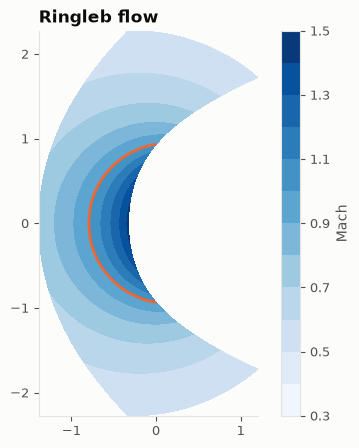

In [3]:
K, QN = np.meshgrid(np.linspace(0.7, 1.2, 60), np.linspace(0, 1, 120))
Q = 0.5 + (K - 0.5) * QN * (1 - 1e-9)
fig, ax = plt.subplots(figsize=(6, 5))
for b in (1, -1):
    x, y, rho, u, v, p = ringleb(Q, K, b)
    cs = ax.contourf(x, y, np.hypot(u, v) / np.sqrt(1.4 * p / rho), levels=np.linspace(0.3, 1.5, 13), cmap="Blues")
    ax.contour(x, y, np.hypot(u, v) / np.sqrt(1.4 * p / rho), levels=[1.0], colors=P.SERIES[1])
ax.set_aspect("equal"); ax.grid(False); fig.colorbar(cs, label="Mach"); ax.set_title("Ringleb flow");

The trained networks (seed 0), against the exact solutions:

In [4]:
for case in ("ringleb", "wedge_plain", "wedge_viscous", "wedge_weighted"):
    model, _ = io.load_checkpoint(CK / f"phase5_{case}.pt", EulerPINN, DEVICE)
    cls = RinglebProblem if case == "ringleb" else WedgeProblem
    m = cls(model, n_interior=64, n_boundary=32, device=DEVICE).evaluate(model)
    extra = f", shock angle {m['beta_deg']:.2f} deg" if "beta_deg" in m else ""
    print(f"{case:15s} state error {m['error']:.3e}" + extra)

ringleb         state error 1.429e-03
wedge_plain     state error 5.315e-02, shock angle 37.48 deg
wedge_viscous   state error 4.560e-02, shock angle 38.37 deg
wedge_weighted  state error 5.598e-02, shock angle 36.94 deg


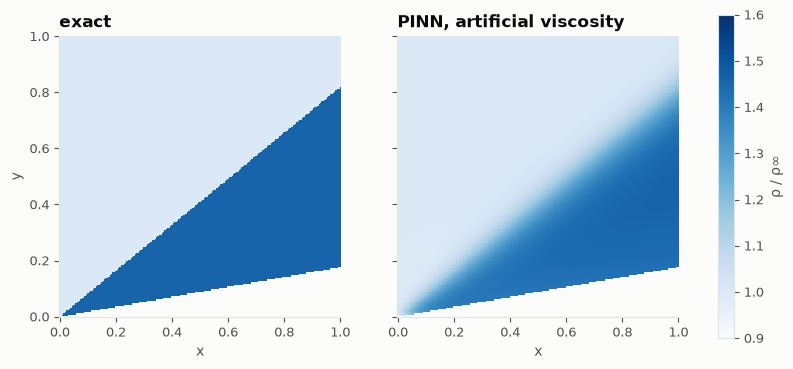

In [5]:
g = np.linspace(0, 1, 201)
X, Y = np.meshgrid(g, g)
pts = np.column_stack([X.ravel(), Y.ravel()])
below = pts[:, 1] < pts[:, 0] * np.tan(10 * DEG)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
model, _ = io.load_checkpoint(CK / "phase5_wedge_viscous.pt", EulerPINN, DEVICE)
with torch.no_grad():
    rho_pinn = model(torch.tensor(pts, dtype=torch.float32))[:, 0].numpy()
for ax, rho, title in ((axes[0], wedge_field(*pts.T, 10 * DEG, 2.0)[:, 0], "exact"),
                       (axes[1], rho_pinn, "PINN, artificial viscosity")):
    im = ax.pcolormesh(X, Y, np.where(below, np.nan, rho).reshape(X.shape), cmap="Blues", vmin=0.9, vmax=1.6, shading="auto")
    ax.set_aspect("equal"); ax.grid(False); ax.set_title(title); ax.set_xlabel("x")
axes[0].set_ylabel("y"); fig.colorbar(im, ax=axes, label="ρ / ρ∞");